# 01 - Exploración de variables de la base del ICFES

Exploración de la base registrada en DVC (`data/Base de Datos (MIAD).dta`). Esta base une los resultados de Saber 11, la matrícula en educación superior (hasta cuatro programas) y Saber Pro / TyT.

Se revisa:

1. Qué variables están disponibles **antes** del ingreso a educación superior, que son las únicas que puede usar el modelo.
2. Calidad de los datos: duplicados, faltantes, rangos y consistencia de la variable objetivo.
3. Relación del ingreso a educación superior (`enroll_full`) con los puntajes, el hogar y el colegio.

La base se lee por bloques y solo con las columnas necesarias, para no cargar los 3.1 GB en memoria.

## Librerías

In [1]:
# Librerías necesarias para el proyecto

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

In [2]:
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 120)

RUTA = Path("data") / "Base de Datos (MIAD).dta"
SALIDA = Path("reports") / "exploracion"
SALIDA.mkdir(parents=True, exist_ok=True)

TAM_BLOQUE = 200_000
FRAC_MUESTRA = 0.05
SEMILLA = 2026

print("¿Existe la base?:", RUTA.is_file())
if RUTA.is_file():
    print("Tamaño (GB):", round(RUTA.stat().st_size / 1024**3, 3))

¿Existe la base?: True
Tamaño (GB): 3.112


## 1. Variables disponibles y clasificación

La variable objetivo es `enroll_full` (ingreso a educación superior). Las variables de programa, institución y Saber Pro solo existen para quien ingresó: si se usan como predictoras el modelo "ve" la respuesta (fuga de información), por lo que se separan. Tampoco se usan como predictoras las otras versiones del objetivo (`enroll_5years`, `enroll_3years`, `enroll_tti`).

In [3]:
with pd.read_stata(RUTA, iterator=True, convert_categoricals=False) as lector:
    etiquetas = lector.variable_labels()
    primeras = lector.read(5)

columnas = list(primeras.columns)

OBJETIVO = "enroll_full"
OBJETIVOS_ALTERNOS = ["enroll_5years", "enroll_3years", "enroll_tti"]
IDENTIFICADORES = ["estu_consecutivo", "estu_fechanacimiento", "periodo",
                   "cole_cod_dane_establecimiento", "cole_cod_mcpio_ubicacion"]
POSTERIORES_FIJAS = ["prim_year1", "year_enrolled", "ventana_sb11_es", "ventana_sb11_protyt"]
PREFIJOS_PROGRAMA = ("ies", "programa_id", "prim_sem", "program_code", "enroll",
                     "year_activo", "year_enrolls", "id_mun_programa")

def es_posterior(var):
    if var in POSTERIORES_FIJAS or var.endswith("_p"):
        return True
    return var[-1] in "1234" and var[:-1].startswith(PREFIJOS_PROGRAMA)

def clasificar(var):
    if var == OBJETIVO:
        return "Objetivo"
    if var in OBJETIVOS_ALTERNOS:
        return "Objetivo alterno (excluir)"
    if var in IDENTIFICADORES:
        return "Identificador"
    if es_posterior(var):
        return "Posterior al ingreso (excluir)"
    return "Predictora candidata"

tabla_variables = pd.DataFrame({
    "Variable": columnas,
    "Etiqueta": [etiquetas.get(c, "") for c in columnas],
    "Tipo": primeras.dtypes.astype(str).values,
    "Clasificación": [clasificar(c) for c in columnas],
})

print("Número de variables:", len(columnas))
display(tabla_variables["Clasificación"].value_counts())
display(tabla_variables[tabla_variables["Clasificación"].isin(["Objetivo", "Predictora candidata"])])
tabla_variables.to_csv(SALIDA / "clasificacion_variables.csv", index=False)

Número de variables: 89


Clasificación
Posterior al ingreso (excluir)    57
Predictora candidata              23
Identificador                      5
Objetivo alterno (excluir)         3
Objetivo                           1
Name: count, dtype: int64

,Variable,Etiqueta,Tipo,Clasificación
1,año,Año de presentación del examen,int16,Predictora candidata
3,estu_genero,Género,int8,Predictora candidata
4,estu_edad,Edad del evaluado al presentar el examen,int8,Predictora candidata
6,estu_etnia,Grupo étnico minoritario al que pertenece,str,Predictora candidata
8,cole_genero,Género de la población del establecimiento,str,Predictora candidata
9,cole_calendario,Calendario académico del establecimiento,str,Predictora candidata
10,cole_area_ubicacion,Área de ubicación de la sede,str,Predictora candidata
11,cole_jornada,Jornada de la sede,str,Predictora candidata
13,cole_cod_depto_ubicacion,Código DANE del departamento de la sede,int8,Predictora candidata
14,punt_matematicas,Puntaje en matemáticas,int16,Predictora candidata


In [4]:
PREDICTORAS = tabla_variables.loc[
    tabla_variables["Clasificación"] == "Predictora candidata", "Variable"
].tolist()

CATEGORICAS = [c for c in [
    "año", "estu_genero", "estu_edad", "estu_etnia", "estu_tieneetnia",
    "cole_genero", "cole_calendario", "cole_area_ubicacion", "cole_jornada",
    "cole_naturaleza", "cole_cod_depto_ubicacion", "fami_educacionmadre",
    "fami_estratovivienda", "fami_cuartoshogar", "fami_personashogar",
    "fami_tienecomputador", "fami_tieneinternet",
] if c in PREDICTORAS]

NUMERICAS = [c for c in PREDICTORAS
             if c not in CATEGORICAS and pd.api.types.is_numeric_dtype(primeras[c])]

print("Predictoras candidatas:", len(PREDICTORAS))
print("Categóricas:", CATEGORICAS)
print("Numéricas:", NUMERICAS)

Predictoras candidatas: 23
Categóricas: ['año', 'estu_genero', 'estu_edad', 'estu_etnia', 'estu_tieneetnia', 'cole_genero', 'cole_calendario', 'cole_area_ubicacion', 'cole_jornada', 'cole_naturaleza', 'cole_cod_depto_ubicacion', 'fami_educacionmadre', 'fami_estratovivienda', 'fami_cuartoshogar', 'fami_personashogar', 'fami_tienecomputador', 'fami_tieneinternet']
Numéricas: ['punt_matematicas', 'punt_ingles', 'punt_lectura_critica', 'punt_c_naturales', 'punt_global', 'estu_inse_individual']


## 2. Lectura por bloques

En una sola pasada se acumulan: conteos del objetivo por cada variable categórica, faltantes, mínimos y máximos de las numéricas, el cruce del objetivo con sus versiones alternas y un hash del identificador del estudiante para revisar duplicados. Además se guarda una muestra aleatoria del 5 % para las gráficas. Los textos vacíos (`""`) se tratan como faltantes.

In [5]:
usar = ["estu_consecutivo"] + PREDICTORAS + [OBJETIVO] + \
       [c for c in OBJETIVOS_ALTERNOS + ["ventana_sb11_es"] if c in columnas]

conteos = {v: [] for v in CATEGORICAS}
cruces = []
faltantes = pd.Series(0, index=PREDICTORAS + [OBJETIVO], dtype="int64")
minimos, maximos = {}, {}
hashes, muestras = [], []
total = 0

lector = pd.read_stata(RUTA, columns=usar, chunksize=TAM_BLOQUE,
                       convert_categoricals=False)

for i, bloque in enumerate(lector):
    texto = bloque.select_dtypes(exclude="number").columns
    bloque[texto] = bloque[texto].replace("", np.nan)

    total += len(bloque)
    faltantes += bloque[PREDICTORAS + [OBJETIVO]].isna().sum()

    for v in CATEGORICAS:
        conteos[v].append(bloque.groupby(v, dropna=False)[OBJETIVO].agg(["count", "sum"]))

    for v in NUMERICAS:
        minimos[v] = min(minimos.get(v, np.inf), bloque[v].min())
        maximos[v] = max(maximos.get(v, -np.inf), bloque[v].max())

    cruces.append(bloque.groupby([OBJETIVO] + [c for c in OBJETIVOS_ALTERNOS if c in bloque],
                                 dropna=False).size())

    hashes.append(pd.util.hash_array(bloque["estu_consecutivo"].astype(str).to_numpy()))
    muestras.append(bloque.sample(frac=FRAC_MUESTRA, random_state=SEMILLA + i))

muestra = pd.concat(muestras, ignore_index=True)
del muestras

print("Registros leídos:", f"{total:,}")
print("Tamaño de la muestra:", f"{len(muestra):,}")

Registros leídos: 7,138,927
Tamaño de la muestra: 356,946


## 3. Calidad de los datos

In [6]:
hashes = np.concatenate(hashes)
duplicados = len(hashes) - len(np.unique(hashes))
print("estu_consecutivo duplicados:", f"{duplicados:,}")

ingreso = muestra[OBJETIVO].value_counts(dropna=False)
print("\nDistribución de enroll_full en la muestra (%):")
print((ingreso / len(muestra) * 100).round(2))

calidad = pd.DataFrame({
    "Faltantes": faltantes,
    "% faltantes": (faltantes / total * 100).round(2),
})
calidad["Mínimo"] = pd.Series(minimos)
calidad["Máximo"] = pd.Series(maximos)
calidad = calidad.sort_values("% faltantes", ascending=False)

display(calidad)
calidad.to_csv(SALIDA / "calidad_predictoras.csv")

estu_consecutivo duplicados: 0

Distribución de enroll_full en la muestra (%):
enroll_full
1    58.18
0    41.82
Name: count, dtype: float64


,Faltantes,% faltantes,Mínimo,Máximo
estu_etnia,5358404,75.06,NaN,NaN
estu_tieneetnia,3036271,42.53,NaN,NaN
estu_inse_individual,1110472,15.56,11.347243,88.36628
punt_global,1065514,14.93,0.000000,500.00000
fami_tienecomputador,93953,1.32,NaN,NaN
fami_cuartoshogar,90416,1.27,NaN,NaN
fami_personashogar,85604,1.20,NaN,NaN
fami_estratovivienda,47273,0.66,NaN,NaN
punt_ingles,29313,0.41,-1.000000,100.00000
fami_tieneinternet,21194,0.30,NaN,NaN


In [7]:
# Consistencia del objetivo con sus versiones alternas
cruce = pd.concat(cruces).groupby(level=list(range(len(cruces[0].index.names)))).sum()
cruce = cruce.rename("Estudiantes").reset_index()
cruce["%"] = (cruce["Estudiantes"] / total * 100).round(2)
display(cruce)
cruce.to_csv(SALIDA / "consistencia_objetivo.csv", index=False)

if "ventana_sb11_es" in muestra:
    print("\nVentana entre Saber 11 e ingreso (años), solo quienes ingresaron (muestra):")
    display(muestra.loc[muestra[OBJETIVO] == 1, "ventana_sb11_es"]
            .value_counts(dropna=False).sort_index().to_frame("Estudiantes"))

,enroll_full,enroll_5years,enroll_3years,enroll_tti,Estudiantes,%
0,0,0,0,0,2980035,41.74
1,1,0,0,0,570372,7.99
2,1,1,0,0,747368,10.47
3,1,1,1,0,1642132,23.00
4,1,1,1,1,1199020,16.80



Ventana entre Saber 11 e ingreso (años), solo quienes ingresaron (muestra):


,Estudiantes
ventana_sb11_es,
0.0,4142
1.0,59936
2.0,47960
3.0,34084
4.0,21870
5.0,15386
6.0,9338
7.0,5672
8.0,3496


## 4. Puntajes de Saber 11 según ingreso a educación superior

In [8]:
puntajes = [c for c in ["punt_matematicas", "punt_lectura_critica", "punt_c_naturales",
                        "punt_ingles", "punt_global", "estu_inse_individual"]
            if c in muestra.columns]

resumen_puntajes = (
    muestra.groupby(OBJETIVO)[puntajes]
    .describe(percentiles=[0.25, 0.5, 0.75])
    .round(2)
    .T
)
display(resumen_puntajes)
resumen_puntajes.to_csv(SALIDA / "puntajes_por_ingreso.csv")

enroll_full                         0          1
punt_matematicas     count  149262.00  207684.00
                     mean       46.26      53.64
                     std        11.22      11.74
                     min         0.00       0.00
                     25%        38.00      46.00
                     50%        46.00      53.00
                     75%        53.00      61.00
                     max       127.00     125.00
punt_lectura_critica count  149262.00  207684.00
                     mean       48.62      55.29
                     std         9.71       9.86
                     min         0.00       0.00
                     25%        42.00      48.00
                     50%        48.00      55.00
                     75%        55.00      62.00
                     max       100.00     100.00
punt_c_naturales     count  149262.00  207684.00
                     mean       46.29      53.49
                     std         9.28      10.26
                     min         0.00       0.00
                     25%        40.00      46.00
                     50%        45.00      53.00
                     75%        52.00      60.00
                     max       100.00     100.00
punt_ingles          count  148099.00  207356.00
                     mean       46.04      52.87
                     std        10.86      12.88
                     min        -1.00      -1.00
                     25%        39.00      43.00
                     50%        44.00      51.00
                     75%        51.00      60.00
                     max       100.00     100.00
punt_global          count  132235.00  171375.00
                     mean      233.33     271.13
                     std        45.42      47.86
                     min         0.00       0.00
                     25%       200.00     237.00
                     50%       228.00     270.00
                     75%       262.00     304.00
                     max       472.00     476.00
estu_inse_individual count  131371.00  169912.00
                     mean       47.72      53.16
                     std         8.93       9.67
                     min        12.78      13.76
                     25%        41.50      46.52
                     50%        47.31      52.73
                     75%        53.38      59.11
                     max        88.37      88.37

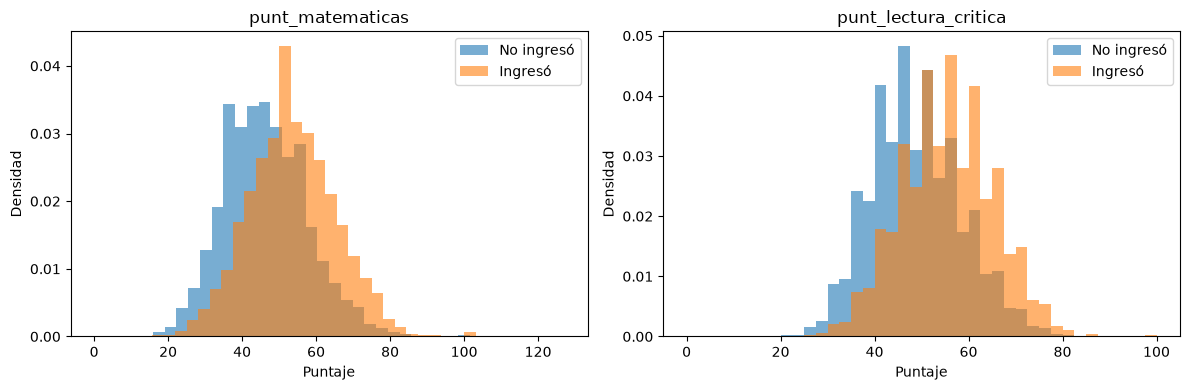

In [9]:
graf_puntajes = [c for c in ["punt_matematicas", "punt_lectura_critica"] if c in muestra]

fig, ejes = plt.subplots(1, len(graf_puntajes), figsize=(6 * len(graf_puntajes), 4))
ejes = np.atleast_1d(ejes)

for eje, var in zip(ejes, graf_puntajes):
    for valor, nombre in [(0, "No ingresó"), (1, "Ingresó")]:
        eje.hist(muestra.loc[muestra[OBJETIVO] == valor, var].dropna(),
                 bins=40, alpha=0.6, density=True, label=nombre)
    eje.set_title(var)
    eje.set_xlabel("Puntaje")
    eje.set_ylabel("Densidad")
    eje.legend()

plt.tight_layout()
plt.savefig(SALIDA / "hist_puntajes.png", dpi=120)
plt.show()

,Tasa ingreso (%)
decil_mat,
1,32.04
2,40.47
3,46.79
4,52.07
5,57.28
6,61.53
7,64.66
8,70.68
9,76.10


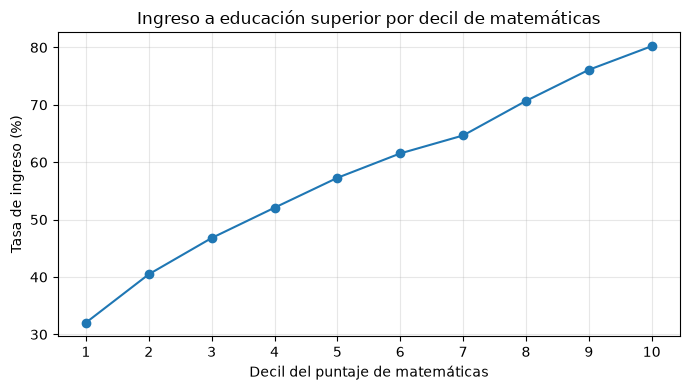

In [10]:
muestra["decil_mat"] = pd.qcut(muestra["punt_matematicas"].rank(method="first"), 10,
                               labels=range(1, 11))
tasa_decil = (muestra.groupby("decil_mat", observed=True)[OBJETIVO].mean() * 100).round(2)
display(tasa_decil.to_frame("Tasa ingreso (%)"))

plt.figure(figsize=(7, 4))
plt.plot(tasa_decil.index.astype(int), tasa_decil.values, marker="o")
plt.xlabel("Decil del puntaje de matemáticas")
plt.ylabel("Tasa de ingreso (%)")
plt.title("Ingreso a educación superior por decil de matemáticas")
plt.xticks(range(1, 11))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(SALIDA / "tasa_decil_matematicas.png", dpi=120)
plt.show()

tasa_decil.to_csv(SALIDA / "tasa_decil_matematicas.csv")

## 5. Tasa de ingreso por variable categórica (base completa)

In [11]:
def consolidar(var):
    tabla = pd.concat(conteos[var]).groupby(level=0, dropna=False).sum()
    tabla = tabla.rename(columns={"count": "Estudiantes", "sum": "Ingresaron"})
    tabla["% del total"] = (tabla["Estudiantes"] / total * 100).round(2)
    tabla["Tasa ingreso (%)"] = (tabla["Ingresaron"] / tabla["Estudiantes"] * 100).round(2)
    return tabla

tablas = {v: consolidar(v) for v in CATEGORICAS}

for v in CATEGORICAS:
    print(f"\n=== {v} | {etiquetas.get(v, '')} ===")
    display(tablas[v])
    tablas[v].to_csv(SALIDA / f"tasa_{v}.csv")


=== año | Año de presentación del examen ===


,Estudiantes,Ingresaron,% del total,Tasa ingreso (%)
año,,,,
2012,511248,344788,7.16,67.44
2013,532366,365649,7.46,68.68
2014,531862,357997,7.45,67.31
2015,532780,355430,7.46,66.71
2016,535986,357916,7.51,66.78
2017,510697,336883,7.15,65.97
2018,505852,326039,7.09,64.45
2019,513223,324440,7.19,63.22
2020,483284,302845,6.77,62.66



=== estu_genero | Género ===


,Estudiantes,Ingresaron,% del total,Tasa ingreso (%)
estu_genero,,,,
0,3273137,1910359,45.85,58.36
1,3865790,2248533,54.15,58.16



=== estu_edad | Edad del evaluado al presentar el examen ===


...

,Estudiantes,Ingresaron,% del total,Tasa ingreso (%)
fami_personashogar,,,,
1.0,523168,283280,7.33,54.15
2.0,3488686,2157087,48.87,61.83
3.0,2270543,1303080,31.81,57.39
4.0,557296,275127,7.81,49.37
5.0,213630,99179,2.99,46.43
NaN,85604,41139,1.20,48.06



=== fami_tienecomputador | Hogar posee computador ===


,Estudiantes,Ingresaron,% del total,Tasa ingreso (%)
fami_tienecomputador,,,,
0.0,2933002,1284508,41.08,43.79
1.0,4111972,2828160,57.60,68.78
NaN,93953,46224,1.32,49.20



=== fami_tieneinternet | Hogar cuenta con servicio o conexión a internet ===


,Estudiantes,Ingresaron,% del total,Tasa ingreso (%)
fami_tieneinternet,,,,
0.0,2674722,1273558,37.47,47.61
1.0,4443011,2878678,62.24,64.79
NaN,21194,6656,0.30,31.41


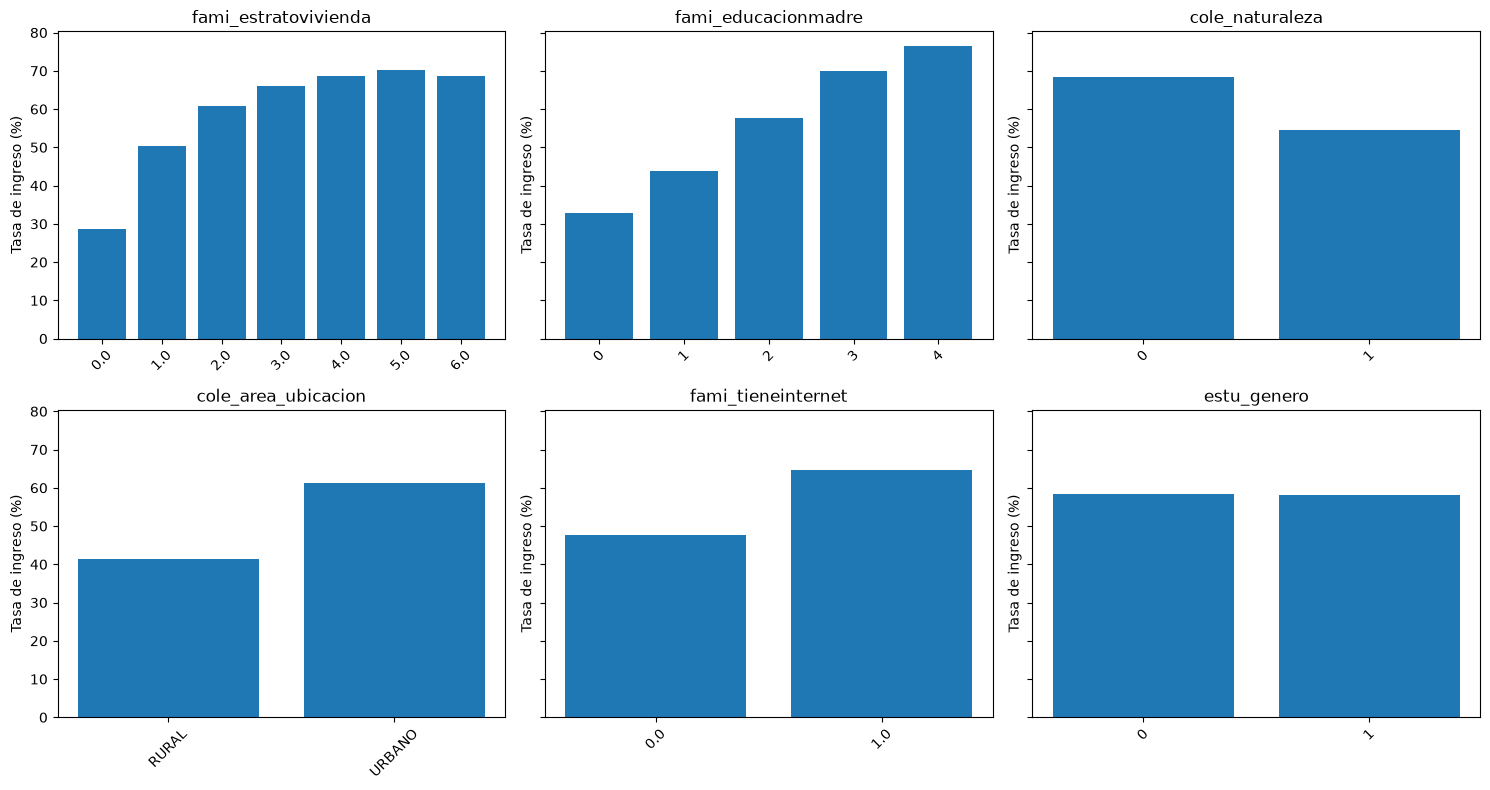

In [12]:
graficar = [v for v in ["fami_estratovivienda", "fami_educacionmadre", "cole_naturaleza",
                        "cole_area_ubicacion", "fami_tieneinternet", "estu_genero"]
            if v in tablas]

filas = int(np.ceil(len(graficar) / 3))
fig, ejes = plt.subplots(filas, 3, figsize=(15, 4 * filas), sharey=True)
ejes = np.atleast_1d(ejes).ravel()

for eje, v in zip(ejes, graficar):
    t = tablas[v][tablas[v].index.notna()]
    t = t[t["% del total"] >= 0.1]
    eje.bar(t.index.astype(str), t["Tasa ingreso (%)"])
    eje.set_title(v)
    eje.tick_params(axis="x", rotation=45)
    eje.set_ylabel("Tasa de ingreso (%)")

for eje in ejes[len(graficar):]:
    eje.axis("off")

plt.tight_layout()
plt.savefig(SALIDA / "tasa_categoricas.png", dpi=120)
plt.show()

## 6. Correlación de las predictoras numéricas y ordinales con el ingreso

,Correlación con enroll_full
punt_global,0.372
punt_c_naturales,0.339
punt_lectura_critica,0.318
punt_matematicas,0.301
estu_inse_individual,0.277
punt_ingles,0.269
fami_tienecomputador,0.252
estu_edad,-0.240
fami_educacionmadre,0.237
fami_tieneinternet,0.171


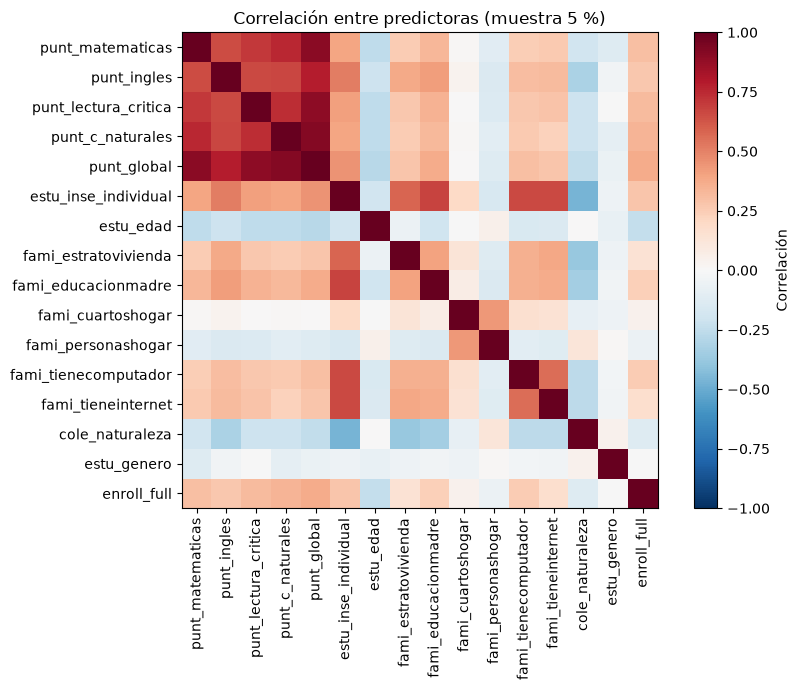

In [13]:
ordinales = [c for c in ["estu_edad", "fami_estratovivienda", "fami_educacionmadre",
                         "fami_cuartoshogar", "fami_personashogar", "fami_tienecomputador",
                         "fami_tieneinternet", "cole_naturaleza", "estu_genero"]
             if c in muestra and pd.api.types.is_numeric_dtype(muestra[c])]
variables_corr = [c for c in NUMERICAS + ordinales if muestra[c].notna().any()] + [OBJETIVO]

corr = muestra[variables_corr].corr()
display(corr[OBJETIVO].drop(OBJETIVO).sort_values(key=abs, ascending=False)
        .round(3).to_frame("Correlación con enroll_full"))

plt.figure(figsize=(9, 7))
plt.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
plt.colorbar(label="Correlación")
plt.xticks(range(len(corr)), corr.columns, rotation=90)
plt.yticks(range(len(corr)), corr.columns)
plt.title("Correlación entre predictoras (muestra 5 %)")
plt.tight_layout()
plt.savefig(SALIDA / "correlaciones.png", dpi=120)
plt.show()

corr.round(3).to_csv(SALIDA / "correlaciones.csv")

## 7. Panel visual de analítica descriptiva

Esta sección agrega visualizaciones para presentar los resultados de forma más clara. Todas las figuras se guardan en reports/exploracion/, usando la ruta definida en la sección inicial (SALIDA).

### 7.1. Resumen de la base

Tarjetas con el tamaño de la base, el porcentaje de ingreso observado en la muestra, la cantidad de variables y los identificadores duplicados. El porcentaje de ingreso se calcula sobre la muestra utilizada para los gráficos.

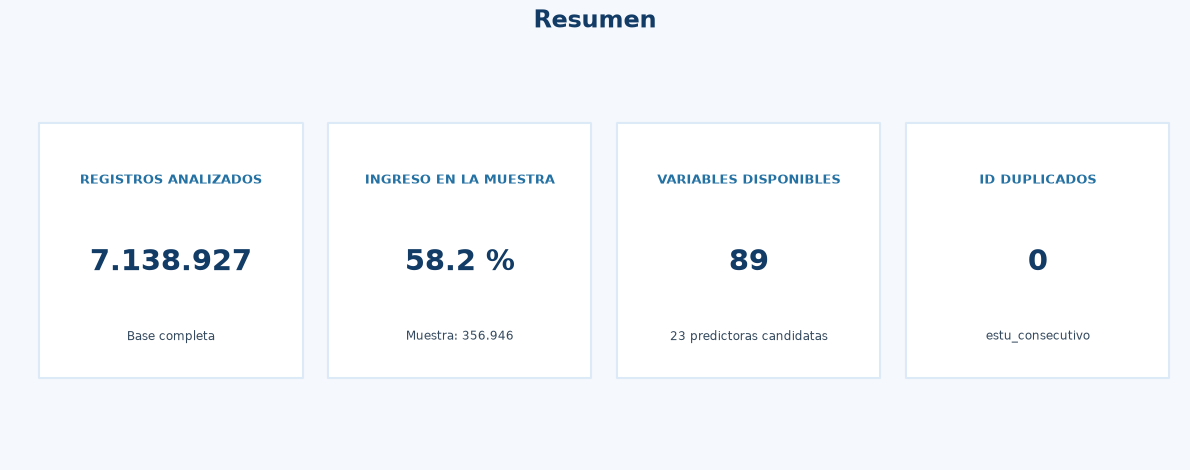

Figura guardada en: reports\exploracion\01_panel_resumen.png


In [14]:
# Crear un panel de indicadores generales y guardarlo en reports
azul_oscuro = "#123B66"
azul_medio = "#2471A3"
azul_claro = "#DCEAF7"
azul_acento = "#4EA5D9"
gris_texto = "#34495E"
gris_fondo = "#F5F8FC"

fig, ax = plt.subplots(figsize=(12, 4.8))
fig.patch.set_facecolor(gris_fondo)
ax.set_facecolor(gris_fondo)
ax.axis("off")

tasa_muestra = muestra[OBJETIVO].mean() * 100
indicadores = [
    ("REGISTROS ANALIZADOS", f"{total:,.0f}".replace(",", "."), "Base completa"),
    ("INGRESO EN LA MUESTRA", f"{tasa_muestra:.1f} %", f"Muestra: {len(muestra):,.0f}".replace(",", ".")),
    ("VARIABLES DISPONIBLES", f"{len(columnas)}", f"{len(PREDICTORAS)} predictoras candidatas"),
    ("ID DUPLICADOS", f"{duplicados:,.0f}".replace(",", "."), "estu_consecutivo"),
]

for i, (titulo, valor, detalle) in enumerate(indicadores):
    x = 0.025 + i * 0.247
    tarjeta = plt.Rectangle((x, 0.20), 0.225, 0.62, transform=ax.transAxes,
                            facecolor="white", edgecolor=azul_claro, linewidth=1.5,
                            joinstyle="round")
    ax.add_patch(tarjeta)
    ax.text(x + 0.1125, 0.68, titulo, transform=ax.transAxes, ha="center",
            va="center", fontsize=9, color=azul_medio, fontweight="bold")
    ax.text(x + 0.1125, 0.48, valor, transform=ax.transAxes, ha="center",
            va="center", fontsize=21, color=azul_oscuro, fontweight="bold")
    ax.text(x + 0.1125, 0.30, detalle, transform=ax.transAxes, ha="center",
            va="center", fontsize=8.5, color=gris_texto)

fig.suptitle("Resumen", fontsize=17,
             fontweight="bold", color=azul_oscuro, y=0.97)
plt.tight_layout()
fig.savefig(SALIDA / "01_panel_resumen.png", dpi=180, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.show()
print("Figura guardada en:", SALIDA / "01_panel_resumen.png")

### 7.2. Calidad de los datos: variables con más faltantes

Gráfico horizontal de las variables con mayor porcentaje de valores faltantes. Sirve para priorizar revisiones antes del modelado. Los porcentajes provienen de la base completa procesada por bloques.

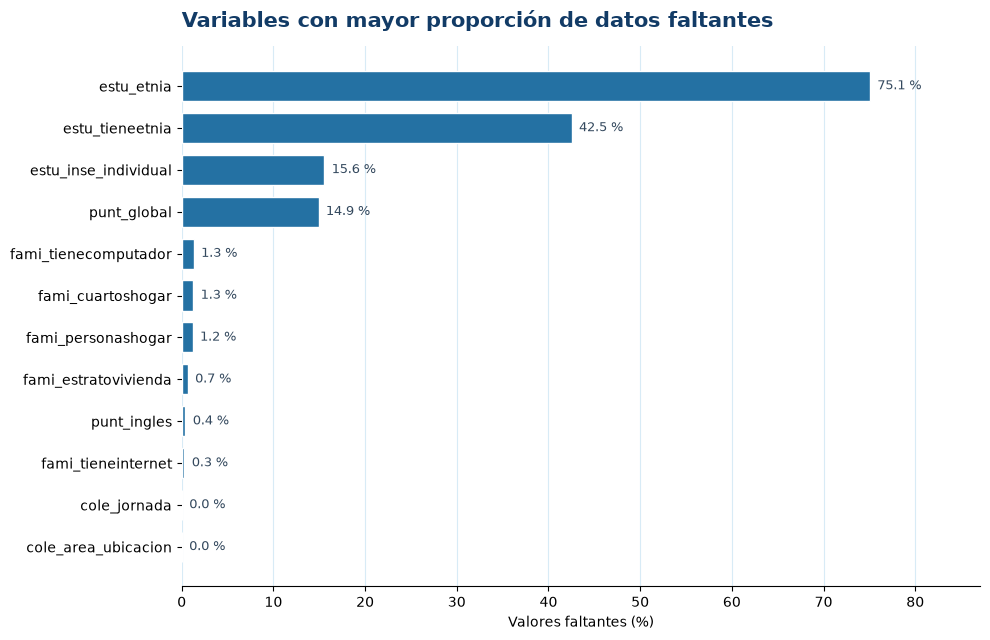

Figura guardada en: reports\exploracion\02_variables_mas_faltantes.png


In [15]:
# Visualizar y guardar las variables con mayor porcentaje de faltantes
faltantes_graf = calidad.loc[calidad["% faltantes"] > 0].head(15).sort_values("% faltantes")

fig, ax = plt.subplots(figsize=(10, 6.5))
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
barras = ax.barh(faltantes_graf.index.astype(str), faltantes_graf["% faltantes"],
                 color=azul_medio, edgecolor="white", height=0.72)

for barra, valor in zip(barras, faltantes_graf["% faltantes"]):
    ax.text(valor + 0.8, barra.get_y() + barra.get_height() / 2,
            f"{valor:.1f} %", va="center", fontsize=9, color=gris_texto)

ax.set_title("Variables con mayor proporción de datos faltantes", loc="left",
             fontsize=15, fontweight="bold", color=azul_oscuro, pad=14)
ax.set_xlabel("Valores faltantes (%)")
ax.set_ylabel("")
ax.spines[["top", "right", "left"]].set_visible(False)
ax.grid(axis="x", alpha=0.22, color=azul_acento)
ax.set_axisbelow(True)
ax.set_xlim(0, min(100, faltantes_graf["% faltantes"].max() + 12) if not faltantes_graf.empty else 100)
plt.tight_layout()
fig.savefig(SALIDA / "02_variables_mas_faltantes.png", dpi=180, bbox_inches="tight")
plt.show()
print("Figura guardada en:", SALIDA / "02_variables_mas_faltantes.png")

### 7.3. Evolución de la tasa de ingreso por cohorte

Se reutiliza el consolidado de `año` para mostrar el porcentaje de ingreso por cohorte. Las cohortes recientes deben interpretarse con cautela: pueden tener menos tiempo de seguimiento, por lo que una tasa baja no implica necesariamente una caída real del ingreso.

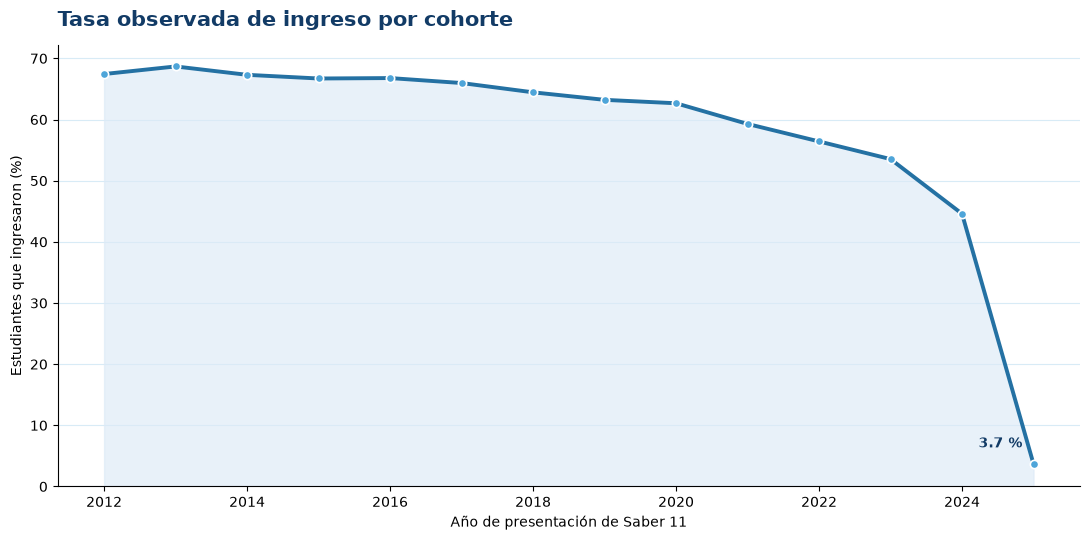

Figura guardada en: reports\exploracion\03_tendencia_ingreso_cohorte.png


In [16]:
# Representar la tasa de ingreso por año y guardar la figura
if "año" in tablas:
    tendencia = tablas["año"].copy()
    tendencia = tendencia.loc[tendencia.index.notna()].copy()
    tendencia["Año_num"] = pd.to_numeric(tendencia.index, errors="coerce")
    tendencia = tendencia.dropna(subset=["Año_num"]).sort_values("Año_num")

    fig, ax = plt.subplots(figsize=(11, 5.5))
    ax.plot(tendencia["Año_num"], tendencia["Tasa ingreso (%)"],
            color=azul_medio, linewidth=2.8, marker="o", markersize=6,
            markerfacecolor=azul_acento, markeredgecolor="white", markeredgewidth=1.2)
    ax.fill_between(tendencia["Año_num"], tendencia["Tasa ingreso (%)"],
                    color=azul_claro, alpha=0.65)

    if len(tendencia) > 0:
        ax.annotate(f'{tendencia["Tasa ingreso (%)"].iloc[-1]:.1f} %',
                    (tendencia["Año_num"].iloc[-1], tendencia["Tasa ingreso (%)"].iloc[-1]),
                    xytext=(-8, 12), textcoords="offset points", ha="right",
                    color=azul_oscuro, fontweight="bold")

    ax.set_title("Tasa observada de ingreso por cohorte", loc="left",
                 fontsize=15, fontweight="bold", color=azul_oscuro, pad=14)
    ax.set_xlabel("Año de presentación de Saber 11")
    ax.set_ylabel("Estudiantes que ingresaron (%)")
    ax.set_ylim(bottom=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.22, color=azul_acento)
    ax.set_axisbelow(True)
    plt.tight_layout()
    fig.savefig(SALIDA / "03_tendencia_ingreso_cohorte.png", dpi=180, bbox_inches="tight")
    plt.show()
    print("Figura guardada en:", SALIDA / "03_tendencia_ingreso_cohorte.png")
else:
    print("No se encontró la variable 'año'; se omite esta visualización.")

### 7.4. Distribución de puntajes según ingreso

Diagramas de caja para comparar la mediana, la dispersión y los valores extremos de los puntajes de matemáticas y lectura crítica entre quienes ingresaron y quienes no. Se usa la muestra ya creada en el análisis; no se eliminan valores extremos.

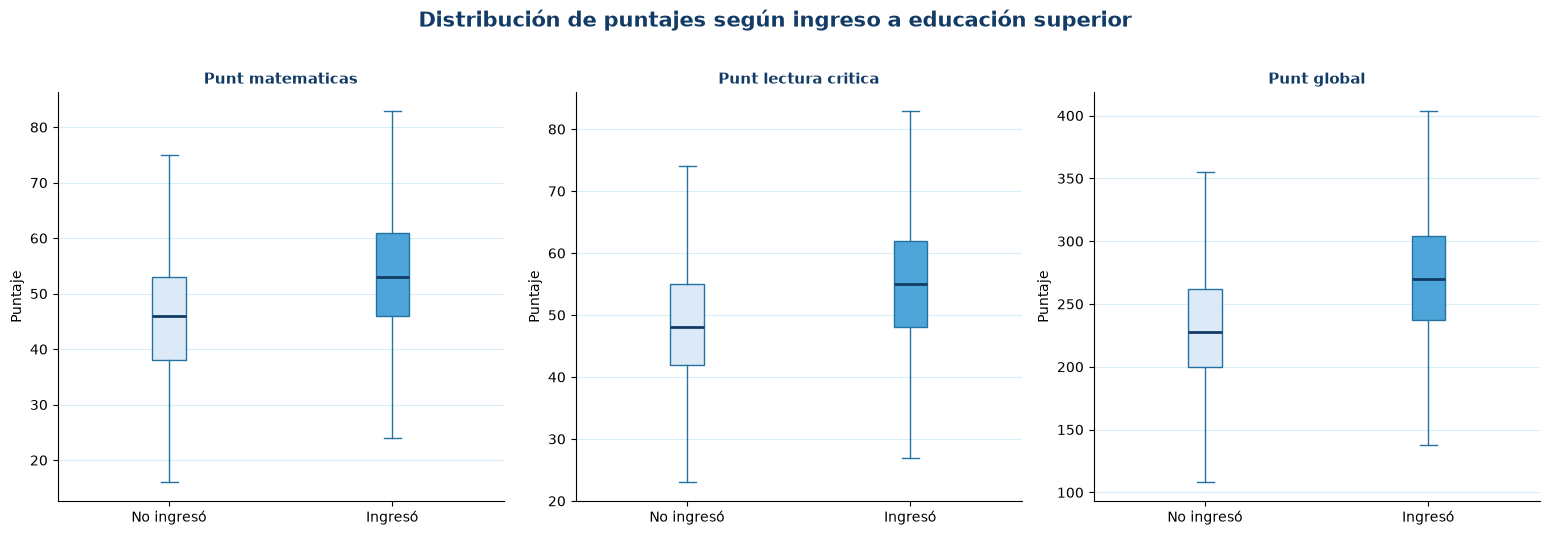

Figura guardada en: reports\exploracion\05_distribucion_puntajes_ingreso.png


In [17]:
# Comparar la distribución de puntajes por condición de ingreso
puntajes_caja = [v for v in ["punt_matematicas", "punt_lectura_critica", "punt_global"]
                 if v in muestra.columns]

if puntajes_caja:
    fig, ejes = plt.subplots(1, len(puntajes_caja),
                             figsize=(5.2 * len(puntajes_caja), 5.2))
    ejes = np.atleast_1d(ejes)

    for eje, var in zip(ejes, puntajes_caja):
        datos_caja = [
            muestra.loc[muestra[OBJETIVO] == 0, var].dropna(),
            muestra.loc[muestra[OBJETIVO] == 1, var].dropna()
        ]
        caja = eje.boxplot(datos_caja, patch_artist=True, showfliers=False,
                           medianprops={"color": azul_oscuro, "linewidth": 2},
                           whiskerprops={"color": azul_medio},
                           capprops={"color": azul_medio})
        for parche, color in zip(caja["boxes"], [azul_claro, azul_acento]):
            parche.set_facecolor(color)
            parche.set_edgecolor(azul_medio)

        eje.set_xticks([1, 2], ["No ingresó", "Ingresó"])
        eje.set_title(var.replace("_", " ").capitalize(), fontsize=11,
                      fontweight="bold", color=azul_oscuro)
        eje.set_ylabel("Puntaje")
        eje.spines[["top", "right"]].set_visible(False)
        eje.grid(axis="y", alpha=0.2, color=azul_acento)
        eje.set_axisbelow(True)

    fig.suptitle("Distribución de puntajes según ingreso a educación superior",
                 fontsize=15, fontweight="bold", color=azul_oscuro, y=1.02)
    plt.tight_layout()
    fig.savefig(SALIDA / "05_distribucion_puntajes_ingreso.png", dpi=180, bbox_inches="tight")
    plt.show()
    print("Figura guardada en:", SALIDA / "05_distribucion_puntajes_ingreso.png")
else:
    print("No se encontraron columnas de puntajes para comparar.")

### 7.5. Composición porcentual del ingreso por estrato
Este gráfico de barras apiladas al 100 % muestra la proporción de estudiantes que ingresaron y no ingresaron a educación superior dentro de cada categoría del estrato de vivienda. Cada barra representa el total de estudiantes de una categoría, distribuido según su condición de ingreso.

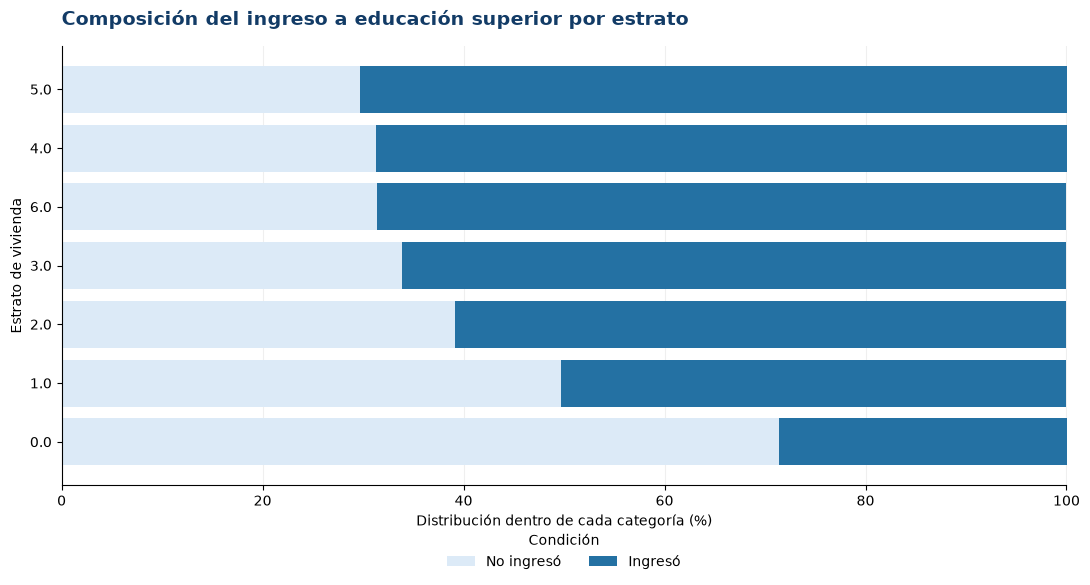

In [18]:
# Comparar la composición porcentual de ingreso entre categorías de estrato

variable_composicion = "fami_estratovivienda"

if variable_composicion in tablas:
    datos_composicion = tablas[variable_composicion].copy()
    datos_composicion = datos_composicion.loc[
        datos_composicion.index.notna()
        & (datos_composicion["Estudiantes"] > 0)
    ]

    datos_composicion = datos_composicion.sort_values(
        "Tasa ingreso (%)"
    )

    if not datos_composicion.empty:
        ingresaron = datos_composicion["Ingresaron"]
        no_ingresaron = datos_composicion["Estudiantes"] - ingresaron

        porcentaje_ingreso = (
            ingresaron / datos_composicion["Estudiantes"] * 100
        )
        porcentaje_no_ingreso = (
            no_ingresaron / datos_composicion["Estudiantes"] * 100
        )

        posiciones = np.arange(len(datos_composicion))

        fig, ax = plt.subplots(figsize=(11, 6))

        ax.barh(
            posiciones,
            porcentaje_no_ingreso,
            color="#DCEAF7",
            label="No ingresó"
        )
        ax.barh(
            posiciones,
            porcentaje_ingreso,
            left=porcentaje_no_ingreso,
            color="#2471A3",
            label="Ingresó"
        )

        ax.set_yticks(posiciones)
        ax.set_yticklabels(datos_composicion.index.astype(str))
        ax.set_xlim(0, 100)
        ax.set_xlabel("Distribución dentro de cada categoría (%)")
        ax.set_ylabel("Estrato de vivienda")

        ax.set_title(
            "Composición del ingreso a educación superior por estrato",
            loc="left",
            fontsize=14,
            fontweight="bold",
            color="#123B66",
            pad=15
        )

        ax.legend(
            title="Condición",
            loc="lower center",
            bbox_to_anchor=(0.5, -0.22),
            ncol=2,
            frameon=False
        )

        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="x", alpha=0.2)
        ax.set_axisbelow(True)

        plt.tight_layout()
        fig.savefig(
            SALIDA / "09_composicion_ingreso_estrato.png",
            dpi=200,
            bbox_inches="tight"
        )
        plt.show()
    else:
        print("No hay categorías con datos para representar.")
else:
    print(f"No se encontró la variable {variable_composicion}.")

### 7.6. Puntaje global e ingreso según nivel educativo de la madre
Este gráfico de burbujas relaciona el puntaje global promedio con la tasa de ingreso a educación superior, agrupando a los estudiantes según el nivel educativo de su madre. La posición horizontal representa el puntaje promedio, la posición vertical indica la tasa de ingreso y el tamaño de cada burbuja representa el número de estudiantes del grupo.

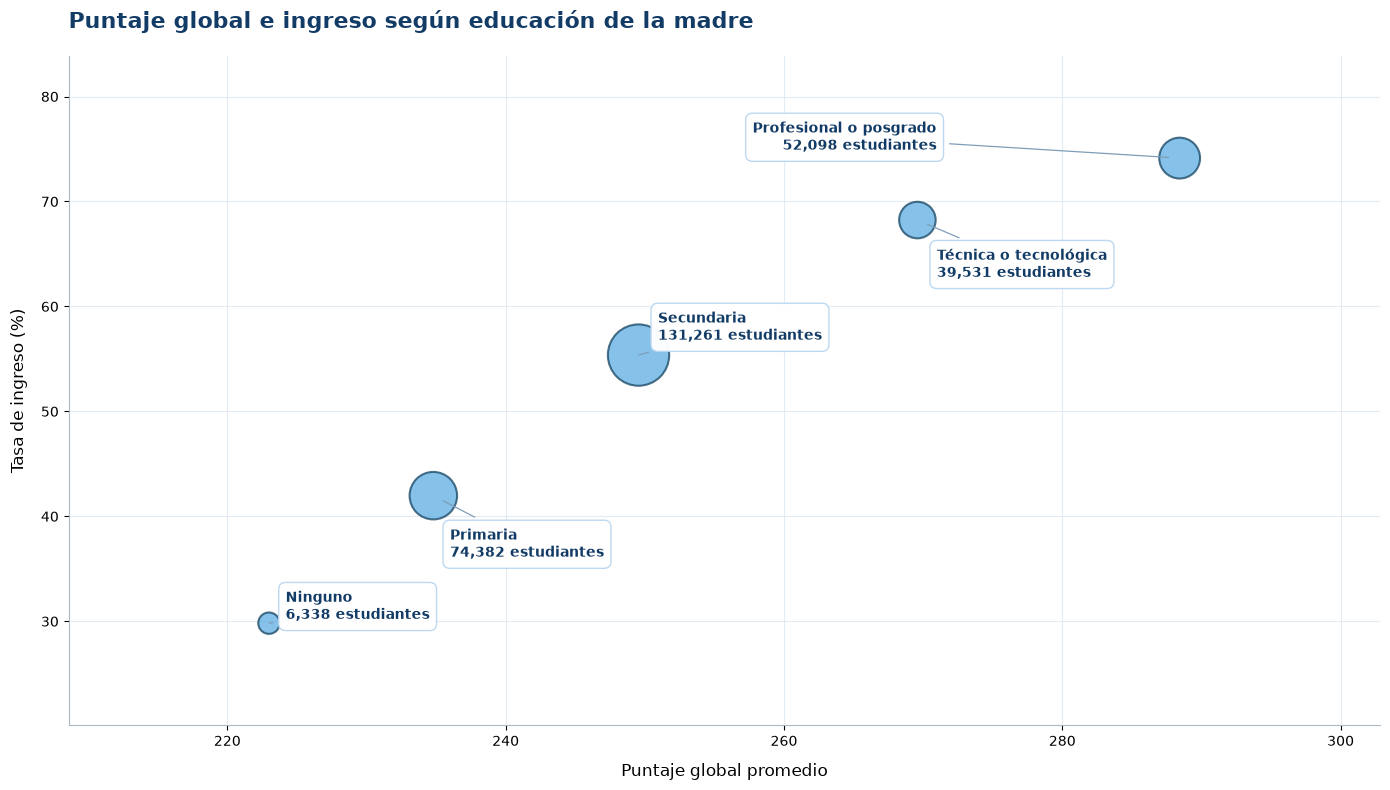

In [19]:

# Comparar el puntaje global, la tasa de ingreso y el volumen de estudiantes por educación de la madre

# Definir las variables del análisis
variable_grupo = "fami_educacionmadre"
variable_puntaje = "punt_global"

etiquetas_educacion = {
    0: "Ninguno",
    1: "Primaria",
    2: "Secundaria",
    3: "Técnica o tecnológica",
    4: "Profesional o posgrado"
}

# Preparar los datos
datos = muestra[
    [variable_grupo, variable_puntaje, OBJETIVO]
].copy()

datos = datos.dropna(
    subset=[variable_grupo, variable_puntaje, OBJETIVO]
)

# Calcular los indicadores por nivel educativo
resumen = datos.groupby(variable_grupo).agg(
    estudiantes=(variable_puntaje, "size"),
    puntaje_promedio=(variable_puntaje, "mean"),
    tasa_ingreso=(OBJETIVO, "mean")
).reset_index()

resumen["tasa_ingreso"] = resumen["tasa_ingreso"] * 100

resumen["Nivel educativo"] = resumen[variable_grupo].map(
    etiquetas_educacion
)

resumen = resumen.dropna(subset=["Nivel educativo"])

# Crear el gráfico de burbujas
fig, ax = plt.subplots(figsize=(14, 8))

tamanos = (
    150
    + 1800 * resumen["estudiantes"] / resumen["estudiantes"].max()
)

ax.scatter(
    resumen["puntaje_promedio"],
    resumen["tasa_ingreso"],
    s=tamanos,
    color="#5DADE2",
    alpha=0.75,
    edgecolors="#154360",
    linewidths=1.5,
    zorder=3
)

# Ubicar las etiquetas para evitar superposiciones
desplazamientos = {
    "Ninguno": (12, 12),
    "Primaria": (12, -35),
    "Secundaria": (14, 20),
    "Técnica o tecnológica": (14, -32),
    "Profesional o posgrado": (-175, 15)
}

for _, fila in resumen.iterrows():

    nombre = fila["Nivel educativo"]
    x = fila["puntaje_promedio"]
    y = fila["tasa_ingreso"]
    cantidad = fila["estudiantes"]

    desplazamiento = desplazamientos.get(nombre, (12, 12))

    ax.annotate(
        f"{nombre}\n{cantidad:,.0f} estudiantes",
        xy=(x, y),
        xytext=desplazamiento,
        textcoords="offset points",
        fontsize=10,
        fontweight="bold",
        color="#123B66",
        ha="left" if desplazamiento[0] > 0 else "right",
        va="center",
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor="white",
            edgecolor="#BBD7F0",
            linewidth=1,
            alpha=0.97
        ),
        arrowprops=dict(
            arrowstyle="-",
            color="#7F9DB9",
            linewidth=0.9,
            shrinkA=4,
            shrinkB=8
        ),
        zorder=4
    )

# Personalizar títulos, ejes y cuadrícula
ax.set_title(
    "Puntaje global e ingreso según educación de la madre",
    loc="left",
    fontsize=16,
    fontweight="bold",
    color="#123B66",
    pad=20
)

ax.set_xlabel(
    "Puntaje global promedio",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Tasa de ingreso (%)",
    fontsize=12,
    labelpad=10
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#AAB7C4")
ax.spines["bottom"].set_color("#AAB7C4")

ax.grid(
    axis="both",
    color="#DCE6F1",
    linestyle="-",
    linewidth=0.8,
    alpha=0.8
)

ax.set_axisbelow(True)
ax.tick_params(axis="both", labelsize=10)
ax.margins(x=0.22, y=0.22)

# Guardar y mostrar la gráfica
plt.tight_layout()

fig.savefig(
    SALIDA / "08_burbujas_educacion_madre.png",
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()


### 7.7. Brecha digital del hogar y tasa de ingreso a educación superior
Este mapa de calor compara la tasa de ingreso a educación superior según la disponibilidad de computador y el acceso a internet en el hogar. Cada celda representa una combinación de estas dos condiciones, y su color indica la tasa de ingreso observada. También se presenta la cantidad de estudiantes que conforman cada grupo.

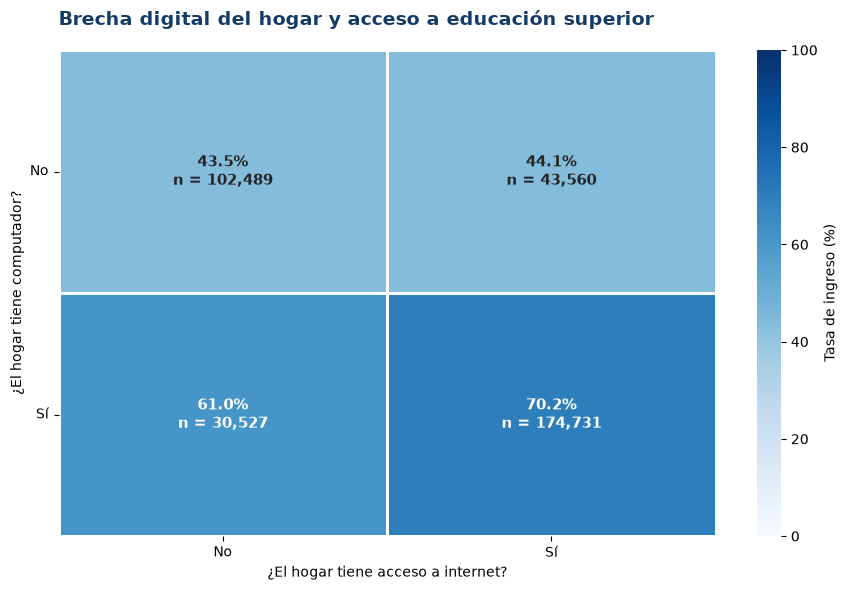

In [20]:

# Analizar la tasa de ingreso según la disponibilidad de computador e internet en el hogar
variable_internet = "fami_tieneinternet"
variable_computador = "fami_tienecomputador"

columnas_necesarias = [
    variable_internet,
    variable_computador,
    OBJETIVO
]

if all(columna in muestra.columns for columna in columnas_necesarias):

    # Preparar los datos del análisis
    datos_digitales = muestra[columnas_necesarias].copy()

    datos_digitales = datos_digitales.dropna(
        subset=columnas_necesarias
    )

    etiquetas_recursos = {
        0: "No",
        1: "Sí",
        "0": "No",
        "1": "Sí"
    }

    datos_digitales["Internet"] = (
        datos_digitales[variable_internet]
        .map(etiquetas_recursos)
    )

    datos_digitales["Computador"] = (
        datos_digitales[variable_computador]
        .map(etiquetas_recursos)
    )

    datos_digitales = datos_digitales.dropna(
        subset=["Internet", "Computador"]
    )

    # Calcular la tasa de ingreso por combinación de recursos
    tabla_tasas = datos_digitales.pivot_table(
        index="Computador",
        columns="Internet",
        values=OBJETIVO,
        aggfunc="mean"
    ) * 100

    tabla_cantidades = datos_digitales.pivot_table(
        index="Computador",
        columns="Internet",
        values=OBJETIVO,
        aggfunc="count"
    )

    orden = ["No", "Sí"]

    tabla_tasas = tabla_tasas.reindex(
        index=orden,
        columns=orden
    )

    tabla_cantidades = tabla_cantidades.reindex(
        index=orden,
        columns=orden
    )

    # Crear las etiquetas con la tasa y el tamaño del grupo
    anotaciones = tabla_tasas.copy().astype(object)

    for fila in orden:
        for columna in orden:
            tasa = tabla_tasas.loc[fila, columna]
            cantidad = tabla_cantidades.loc[fila, columna]

            if pd.notna(tasa) and pd.notna(cantidad):
                anotaciones.loc[fila, columna] = (
                    f"{tasa:.1f}%\n"
                    f"n = {cantidad:,.0f}"
                )
            else:
                anotaciones.loc[fila, columna] = "Sin datos"

    # Visualizar el mapa de calor
    fig, ax = plt.subplots(figsize=(9, 6))

    sns.heatmap(
        tabla_tasas,
        annot=anotaciones,
        fmt="",
        cmap="Blues",
        vmin=0,
        vmax=100,
        linewidths=2,
        linecolor="white",
        mask=tabla_tasas.isna(),
        cbar_kws={"label": "Tasa de ingreso (%)"},
        annot_kws={"fontsize": 11, "fontweight": "bold"},
        ax=ax
    )

    ax.set_title(
        "Brecha digital del hogar y acceso a educación superior",
        loc="left",
        fontsize=14,
        fontweight="bold",
        color="#123B66",
        pad=18
    )

    ax.set_xlabel("¿El hogar tiene acceso a internet?")
    ax.set_ylabel("¿El hogar tiene computador?")

    ax.set_xticklabels(["No", "Sí"], rotation=0)
    ax.set_yticklabels(["No", "Sí"], rotation=0)

    plt.tight_layout()

    # Guardar la gráfica en la carpeta de reportes
    fig.savefig(
        SALIDA / "12_mapa_calor_brecha_digital.png",
        dpi=200,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()

else:
    print(
        "No se encontraron todas las columnas necesarias. "
        "Verifica los nombres de las variables en la base."
    )

### 7.8. Brechas en la tasa de ingreso por grupo

Panel comparativo de la tasa de ingreso en cuatro dimensiones disponibles al presentar Saber 11: estrato de la vivienda, decil de puntaje en matemáticas, área del colegio y acceso a internet en el hogar. La línea punteada marca la tasa global, de modo que se identifica de inmediato qué grupos quedan por debajo. Estos grupos son los que el modelo y el tablero deberían ayudar a priorizar. La celda lee las tablas ya guardadas en `reports/exploracion`, por lo que puede ejecutarse sin procesar de nuevo la base completa.

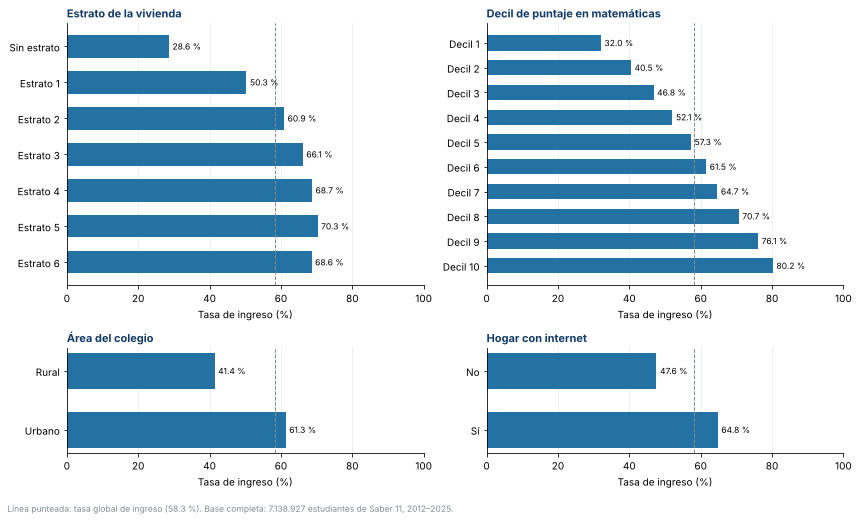

Figura guardada en: reports/exploracion/13_brechas_tasa_ingreso.png


In [21]:
# Panel de brechas: tasa de ingreso por estrato, decil de matemáticas, área e internet
# Celda autocontenida: lee las tablas que el notebook ya guardó en reports/exploracion,
# por lo que se puede ejecutar sin volver a procesar la base completa.
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

SALIDA = Path("reports") / "exploracion"
azul = "#2471A3"
azul_oscuro = "#123B66"
gris = "#7F8C8D"

anios = pd.read_csv(SALIDA / "tasa_año.csv")
tasa_global = 100 * anios["Ingresaron"].sum() / anios["Estudiantes"].sum()

estrato = pd.read_csv(SALIDA / "tasa_fami_estratovivienda.csv").dropna()
estrato = estrato.sort_values("fami_estratovivienda")
decil = pd.read_csv(SALIDA / "tasa_decil_matematicas.csv")
area = pd.read_csv(SALIDA / "tasa_cole_area_ubicacion.csv").dropna()
internet = pd.read_csv(SALIDA / "tasa_fami_tieneinternet.csv").dropna()

paneles = [
    ("Estrato de la vivienda",
     ["Sin estrato" if e == 0 else f"Estrato {int(e)}" for e in estrato["fami_estratovivienda"]],
     estrato["Tasa ingreso (%)"]),
    ("Decil de puntaje en matemáticas",
     [f"Decil {int(d)}" for d in decil["decil_mat"]], decil["enroll_full"]),
    ("Área del colegio",
     [a.capitalize() for a in area["cole_area_ubicacion"]], area["Tasa ingreso (%)"]),
    ("Hogar con internet",
     ["No" if v == 0 else "Sí" for v in internet["fami_tieneinternet"]], internet["Tasa ingreso (%)"]),
]

fig, ejes = plt.subplots(2, 2, figsize=(12, 7.2), gridspec_kw={"height_ratios": [10, 4]})
for eje, (titulo, etiquetas, tasas) in zip(ejes.ravel(), paneles):
    pos = range(len(etiquetas))
    eje.barh(pos, tasas, color=azul, height=0.62)
    eje.axvline(tasa_global, color=gris, lw=1, ls="--")
    for p, v in zip(pos, tasas):
        eje.text(v + 1, p, f"{v:.1f} %", va="center", fontsize=8.5)
    eje.set_yticks(list(pos), etiquetas)
    eje.invert_yaxis()
    eje.set_xlim(0, 100)
    eje.set_xlabel("Tasa de ingreso (%)")
    eje.set_title(titulo, loc="left", fontsize=11, fontweight="bold", color=azul_oscuro)
    eje.spines[["top", "right"]].set_visible(False)
    eje.grid(axis="x", alpha=0.25)
    eje.set_axisbelow(True)

fig.text(0.01, 0.005, f"Línea punteada: tasa global de ingreso ({tasa_global:.1f} %). "
         "Base completa: 7.138.927 estudiantes de Saber 11, 2012–2025.", fontsize=8.5, color=gris)
plt.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(SALIDA / "13_brechas_tasa_ingreso.png", dpi=180, bbox_inches="tight")
plt.show()
print("Figura guardada en:", SALIDA / "13_brechas_tasa_ingreso.png")


### 7.9. Ventana de seguimiento por cohorte

Complementa la sección 7.3 separando las cohortes que aún no completan cinco años de seguimiento (2021–2025). En ellas la caída de la tasa refleja falta de tiempo para observar el ingreso, no un cambio real. Esto define qué cohortes pueden usarse para entrenar un modelo con horizonte de cinco años (2012–2020) y motiva una validación temporal.

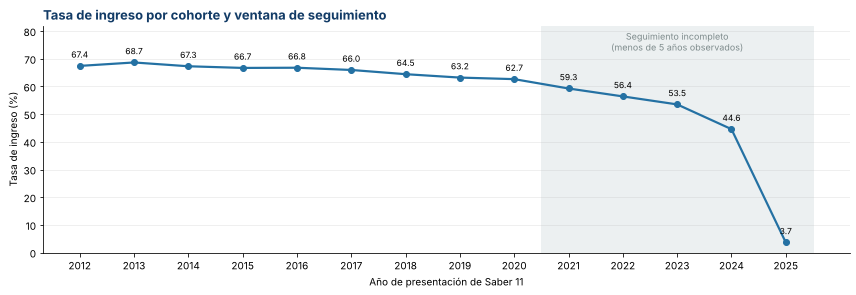

Figura guardada en: reports/exploracion/14_cohortes_ventana_seguimiento.png
Cohortes 2012–2020: tasa entre 62.7 % y 68.7 %


In [22]:
# Tasa de ingreso por cohorte, separando las cohortes sin ventana completa de 5 años
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

SALIDA = Path("reports") / "exploracion"
azul = "#2471A3"
azul_oscuro = "#123B66"
gris = "#7F8C8D"
ULTIMA_COHORTE_COMPLETA = 2020  # cohortes con al menos 5 años de seguimiento (hasta 2025)

cohortes = pd.read_csv(SALIDA / "tasa_año.csv").sort_values("año")

fig, ax = plt.subplots(figsize=(12, 4.2))
ax.axvspan(ULTIMA_COHORTE_COMPLETA + 0.5, cohortes["año"].max() + 0.5, color="#ECF0F1", zorder=0)
ax.text((ULTIMA_COHORTE_COMPLETA + 1 + cohortes["año"].max()) / 2, 73,
        "Seguimiento incompleto\n(menos de 5 años observados)", ha="center", fontsize=9, color=gris)
ax.plot(cohortes["año"], cohortes["Tasa ingreso (%)"], color=azul, lw=2.2, marker="o", ms=6)
for _, fila in cohortes.iterrows():
    ax.text(fila["año"], fila["Tasa ingreso (%)"] + 3, f'{fila["Tasa ingreso (%)"]:.1f}',
            ha="center", fontsize=8.5)
ax.set_xticks(cohortes["año"])
ax.set_ylim(0, 82)
ax.set_xlabel("Año de presentación de Saber 11")
ax.set_ylabel("Tasa de ingreso (%)")
ax.set_title("Tasa de ingreso por cohorte y ventana de seguimiento", loc="left",
             fontsize=13, fontweight="bold", color=azul_oscuro)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
fig.savefig(SALIDA / "14_cohortes_ventana_seguimiento.png", dpi=180, bbox_inches="tight")
plt.show()
print("Figura guardada en:", SALIDA / "14_cohortes_ventana_seguimiento.png")

completas = cohortes[cohortes["año"] <= ULTIMA_COHORTE_COMPLETA]
print(f"Cohortes 2012–{ULTIMA_COHORTE_COMPLETA}: tasa entre "
      f'{completas["Tasa ingreso (%)"].min():.1f} % y {completas["Tasa ingreso (%)"].max():.1f} %')


## 8. Hallazgos

**Tamaño y calidad general**
- La base tiene 7.138.927 estudiantes que presentaron Saber 11 entre 2012 y 2025, sin identificadores duplicados (`estu_consecutivo`).
- De las 89 variables, solo 23 están disponibles al momento de Saber 11 y pueden usarse como predictoras. Las 57 variables de programa, institución y Saber Pro / TyT solo existen para quien ingresó, por lo que no se consideran relevantes para el objetivo del Proyecto.
- Faltantes relevantes: `estu_etnia` (75,1 %), `estu_tieneetnia` (42,5 %), `estu_inse_individual` (15,6 %) y `punt_global` (14,9 %). El resto de predictoras tiene menos de 1,5 %.
- Hay valores que requieren limpieza: categorías de etnia escritas de varias formas (por ejemplo "Zenu (Senu)" y "Zenú"; "S" y "Si" en `estu_tieneetnia`), `punt_ingles` con valor mínimo -1 y `punt_matematicas` con máximo 127, por encima de la escala de las demás pruebas.

**Variable objetivo**
- `enroll_full` vale 1 para el 58,3 % de los estudiantes. Las versiones alternas son anidadas: 16,8 % ingresa de inmediato (`enroll_tti`), 39,8 % dentro de 3 años, 50,3 % dentro de 5 años y 8,0 % ingresa después de 5 años.
- La tasa de ingreso cae en las cohortes recientes (59,3 % en 2021, 44,6 % en 2024 y 3,7 % en 2025). No es un cambio real sino falta de tiempo de seguimiento: la ventana entre Saber 11 y el ingreso llega a 13 años. Para entrenar el modelo hay que definir un horizonte fijo (por ejemplo `enroll_3years` con cohortes hasta 2022) o excluir las cohortes que aún no completan la ventana.

**Relación con las predictoras**
- Los puntajes son el factor más asociado al ingreso: la tasa pasa de 32,0 % en el decil 1 de matemáticas a 80,2 % en el decil 10. `punt_global` es la variable con mayor correlación con el objetivo (0,37), seguida por ciencias naturales (0,34) y lectura crítica (0,32).
- Las condiciones del hogar marcan diferencias grandes: la tasa va de 32,8 % a 76,5 % según la educación de la madre, de 28,6 % (estrato 0) a 70,3 % (estrato 5), y es 25 puntos mayor en hogares con computador (68,8 % frente a 43,8 %).
- Por el colegio: urbano 61,3 % frente a rural 41,4 %; código de naturaleza 0 68,5 % frente a 1 54,7 %; jornadas nocturna y sabatina alrededor de 30 %, frente a 72,1 % en jornada completa.
- La edad al presentar el examen tiene relación negativa: 77,0 % a los 15 años y 31,2 % a los 20.
- El género no muestra diferencias (58,4 % frente a 58,2 %).